# Zonas Potencialmente Inundables partir de un DTM
En este tutorial utilizaremos un Modelo Digital del Terreno para identificar las zonas conectadas con la costa que quedarían por debajo de un determinado nivel de agua y estimaremos qué edificios quedarían potencialmente expuestos.

### Objetivos del tutorial

Al finalizar seremos capaces de:

1. Leer y visualizar un ráster georreferenciado.
2. Entender CRS, transform y NoData
3. Combinar datos ráster y vectoriales.
4. Rasterizar una línea de costa.
5. Aplicar una propagación basada en conectividad.
6. Convertir el resultado ráster a vector.
7. Realizar una intersección espacial con edificios.

## Obtención del ráster georreferenciado
Vamos a descargar un DTM de Argentina
https://www.ign.gob.ar/NuestrasActividades/Geodesia/ModeloDigitalElevaciones/Busqueda

## ¿Qué es un Modelo Digital de Elevaciones?

<br>
Un MDE (Modelo Digital de Elevaciones, Digital Elevation Model o DEM) es una representación digital de la elevación de una superficie mediante una malla o ráster en la que cada píxel contiene un valor de elevación.
<br>
Los modelos de elevación pueden obtenerse a partir de diferentes técnicas, como mediciones topográficas, LiDAR, fotogrametría, imágenes satelitales o drones.
<br>
Dependiendo de qué superficie represente el modelo, podemos distinguir principalmente entre Modelos Digitales del Terreno (MDT) y Modelos Digitales de Superficie (MDS).
<br>

---

<br>

## Diferencia entre MDE, MDT y MDS

<br>

| Sigla | Nombre completo | ¿Qué representa? |
|---|---|---|
| **MDE / DEM** | Modelo Digital de Elevaciones / Digital Elevation Model | Término general para una representación digital de elevaciones. Dependiendo del producto y de cómo se hayan procesado los datos, puede representar diferentes superficies. |
| **MDT / DTM** | Modelo Digital del Terreno / Digital Terrain Model | Representa la elevación del **terreno desnudo**, intentando eliminar edificios, vegetación y otros elementos situados sobre el terreno. |
| **MDS / DSM** | Modelo Digital de Superficie / Digital Surface Model | Representa la **superficie visible**, incluyendo el terreno y elementos situados sobre él, como edificios y vegetación. |

<br>

De forma simplificada:

    MDE / DEM
    Modelo de elevaciones
          │
          ├───────────────┐
          │               │
          ▼               ▼
      MDT / DTM        MDS / DSM
       terreno          superficie
       desnudo           visible
                          +
                       edificios
                       vegetación
                       otros objetos

<br>

![Diferencia entre DEM, DTM y DSM](imagenes/DTM_DSM.svg)

Por Yodin - Based on File:DTM DSM.png by User:MartinOver., CC BY-SA 4.0, https://commons.wikimedia.org/w/index.php?curid=44279694

### ¿Cuál nos interesa para este tutorial?

Para estudiar la propagación potencial de una inundación desde la costa nos interesa principalmente conocer la **elevación del terreno**, por lo que utilizaremos un **MDT (DTM)**.

El modelo de inundación utilizará la elevación de cada píxel para determinar qué zonas se encuentran por debajo de un determinado nivel de agua y cuáles de ellas están conectadas con la costa.

<br>

> **Importante:** la elección del modelo de elevación condiciona el resultado. La resolución espacial y vertical del MDT determina qué elementos del relieve pueden ser representados y, por tanto, qué conexiones o barreras topográficas puede detectar nuestro modelo.


# Librerías geoespaciales en Python

<br>

En Python existen diferentes niveles de abstracción para trabajar con datos geoespaciales. Algunas librerías actúan como **motores de procesamiento**, mientras que otras funcionan como **wrappers** o interfaces de más alto nivel que simplifican su uso.

<br>

| Librería | Tipo | Se apoya en | ¿Para qué se utiliza? | Características |
|---|---|---|---|---|
| **GDAL / OGR** | Motor / librería geoespacial | C/C++ | Lectura, escritura, conversión y procesamiento de datos ráster y vectoriales | Constituye una de las bases del ecosistema geoespacial. **GDAL** se asocia principalmente al procesamiento ráster y **OGR** al vectorial. |
| **Rasterio** | Wrapper / API Python de alto nivel | GDAL | Lectura, escritura y procesamiento habitual de rásteres en Python | Proporciona una interfaz más sencilla y Pythonic que la API de GDAL. Muy adecuado para trabajar con GeoTIFF y combinar datos ráster con NumPy. |
| **Fiona** | Wrapper / API Python para datos vectoriales | OGR | Lectura y escritura de datos vectoriales | Proporciona una interfaz Python para acceder a formatos vectoriales como Shapefile, GeoPackage o GeoJSON. |
| **GeoPandas** | Librería vectorial de alto nivel | pandas + Shapely + librerías de E/S geoespacial | Análisis y manipulación de datos vectoriales | Permite trabajar con puntos, líneas y polígonos mediante una estructura similar a los DataFrame de pandas. |
| **Shapely** | Librería de geometría | GEOS (Motor de operaciones geométricas) | Creación y operaciones con geometrías | Permite trabajar con Point, LineString, Polygon y realizar operaciones geométricas como intersecciones, buffers o uniones. |
| **xarray** | Librería para arrays N-dimensionales etiquetados | NumPy | Análisis de datos multidimensionales | Añade dimensiones, coordenadas y metadatos a los arrays. Especialmente útil para NetCDF, series temporales y datos multidimensionales. |
| **rioxarray** | Extensión geoespacial | xarray + Rasterio | Trabajar con rásteres georreferenciados utilizando el modelo de datos de xarray | Añade CRS, reproyección, recorte y otras operaciones geoespaciales a xarray. Muy útil para NetCDF y colecciones multidimensionales georreferenciadas. |
| **NumPy** | Librería de cálculo numérico | - | Operaciones matemáticas sobre los valores de los píxeles | Permite realizar cálculos, máscaras y operaciones lógicas sobre los arrays que contienen los valores del ráster. |
| **ArcPy** | API Python propietaria | ArcGIS Pro | Automatización y geoprocesamiento dentro de ArcGIS | Permite ejecutar desde Python herramientas de ArcGIS Pro. Requiere el entorno y las licencias correspondientes de ArcGIS. |

### Motor vs. wrapper

Un **wrapper** proporciona una interfaz Python más sencilla para acceder a funcionalidades implementadas por librerías de nivel inferior.

Podemos simplificar parte del ecosistema geoespacial de esta forma:

                          GDAL / OGR
                         /          \
                        /            \
                 Rasterio           Fiona
                    |                 |
                 RÁSTER            VECTOR
                    |
                 rioxarray
                    |
                  xarray
                    |
                  NumPy

En términos generales:

- **GDAL** → motor fundamental para datos geoespaciales, especialmente ráster.
- **OGR** → componente de GDAL orientado a datos vectoriales.
- **Rasterio** → proporciona una interfaz Python de alto nivel para trabajar con rásteres utilizando GDAL.
- **Fiona** → proporciona una interfaz Python para la lectura y escritura de datos vectoriales mediante OGR.
- **GeoPandas** → ofrece un nivel todavía más alto para analizar datos vectoriales mediante GeoDataFrames.


### ¿Qué utilizaremos en este tutorial?

<br>

Cada librería tendrá una función diferente:

- **Rasterio** → leer y procesar el MDT.
- **NumPy** → trabajar con los valores de los píxeles y crear máscaras.
- **GeoPandas** → trabajar con datos vectoriales como la costa y los edificios.
- **Shapely** → crear y manipular geometrías.
- **SciPy** → aplicar la propagación mediante conectividad entre píxeles.
- **OSMnx** → obtener información geográfica de OpenStreetMap.
- **Matplotlib** → visualizar los resultados.

<br>

Una idea importante que utilizaremos durante todo el tutorial es:

    RÁSTER = ARRAY + INFORMACIÓN ESPACIAL

    valores de los píxeles
            +
    transform + CRS

In [1]:
# Matemática y arrays
import numpy as np

# Visualización
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.colors import BoundaryNorm

# Procesamiento raster
import rasterio
from rasterio.plot import show
from rasterio.mask import mask
from rasterio.features import rasterize, shapes

# Procesamiento vectorial / geoespacial
import geopandas as gpd
from shapely.geometry import box, shape

# Procesamiento de máscaras
from scipy.ndimage import binary_dilation

# OSM / datos abiertos
import osmnx as ox



ruta_dtm = "3957-2.img"

# Carga de los datos

In [2]:
with rasterio.open(ruta_dtm) as src: #esto es un rasterio DatasetReader
    dtm = src.read(1).astype(float) #esto es un ndarray. Hacemos el astype porque NaN requiere un array de coma flotante
    transform = src.transform #esto es un affine.Affine
    nodata = src.nodata #esto es un float
    crs = src.crs
    bounds = src.bounds

### ¿Qué hemos cargado?

Al abrir el MDT con Rasterio obtenemos tanto los **valores de elevación** como la información necesaria para localizar esos valores en el espacio.

| Variable | ¿Qué contiene? |
|---|---|
| **`dtm`** | Matriz (array) con la elevación de cada píxel. |
| **`transform`** | Relación entre las filas/columnas del array y las coordenadas espaciales del ráster. |
| **`nodata`** | Valor utilizado para representar la ausencia de datos. |
| **`crs`** | Sistema de referencia de coordenadas (CRS) del ráster. |
| **`bounds`** | Extensión espacial del ráster: coordenadas mínima y máxima en X e Y. |

<br>

**Idea clave:**

    RÁSTER GEOREFERENCIADO = ARRAY DE VALORES + INFORMACIÓN ESPACIAL

                           dtm
                            +
                    transform + CRS

## ¿Por qué mi ráster usa `-999999` en vez de `NaN`?

Muchos formatos ráster tradicionales (como **IMG**, **GeoTIFF antiguos**, **ESRI GRID**, etc.) no almacenan valores *NaN* de forma nativa.  
En su lugar, utilizan un **valor especial** llamado *NoData value*, por ejemplo `-9999`, `-32768` o `-999999`, para indicar que un píxel **no contiene un valor válido**.

### ¿Por qué usar un valor NoData en vez de `NaN`?

- **Compatibilidad**: algunos programas SIG clásicos no soportan NaN, pero sí un valor numérico designado como NoData.  
- **Eficiencia interna**: ciertos formatos están pensados para enteros o para tamaños de celda fijos, donde introducir NaN rompería la estructura del archivo.  
- **Portabilidad**: usar un valor NoData asegura que cualquier software GIS pueda interpretar correctamente las celdas vacías o sin información.  
- **Control explícito**: permite definir exactamente qué valor se considera “inválido” o “fuera de rango”.

En Python, muchas librerías (incluyendo **Rasterio**, **GDAL** y **rioxarray**) detectan automáticamente este valor NoData si el archivo lo tiene definido en su metadata. Sin embargo, a veces no está definido y aparece simplemente como un número en el array.

In [3]:
## Sustituir el valor NoData por `NaN` en Python
# Cuando cargues el ráster, puedes reemplazar el valor NoData por `NaN` para trabajar más cómodamente con NumPy o xarray:
dtm[dtm == nodata] = np.nan

In [4]:
# Otra opción es cargar el dtm así porque rasterio ya sabe qué píxeles son noData a partir de los metadataos
with rasterio.open(ruta_dtm) as src: #esto es un rasterio DatasetReader
    dtm = src.read(1, masked=True).astype("float32")
    transform = src.transform 
    nodata = src.nodata 
    crs = src.crs
    bounds = src.bounds
dtm = dtm.filled(np.nan)

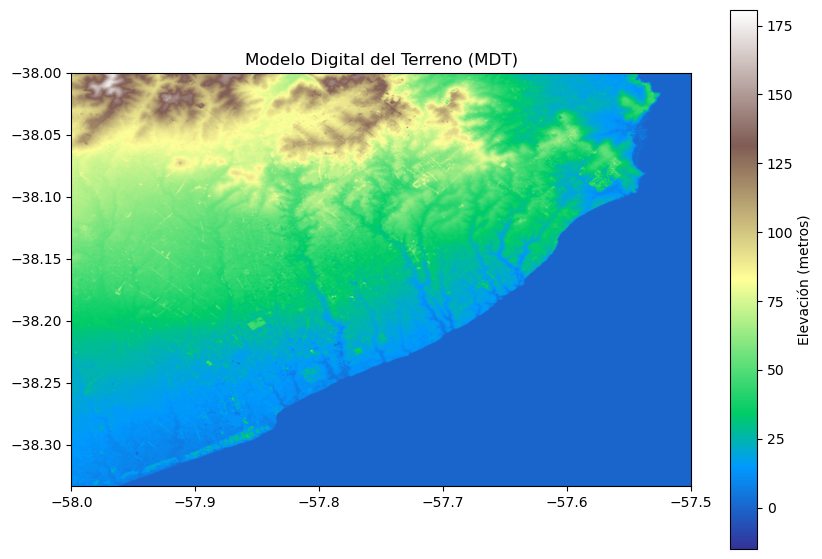

In [5]:
fig, ax = plt.subplots(figsize=(10, 10))

show(
    dtm,
    transform=transform,
    ax=ax,
    cmap='terrain'
)

ax.set_title("Modelo Digital del Terreno (MDT)")

# Barra de color
cbar = plt.colorbar(ax.images[0], ax=ax, shrink=0.7)
cbar.set_label("Elevación (metros)")

plt.show()

### Recortar el dtm

In [6]:
# ¡Atención!  Antes de combinar datos espaciales, todos deben estar en un CRS compatible.
lon_min, lon_max = -57.540, -57.490
lat_min, lat_max = -38.030, -38.010

recorte = box(lon_min, lat_min, lon_max, lat_max)

with rasterio.open(ruta_dtm) as src:
    # Recorta directamente usando el bbox
    out_img, out_transform = mask(src, [recorte], crop=True)
    dtm_crop = out_img[0].astype(float)

# Convertir NoData a NaN
dtm_crop[dtm_crop == nodata] = np.nan

In [7]:
type(recorte)

shapely.geometry.polygon.Polygon

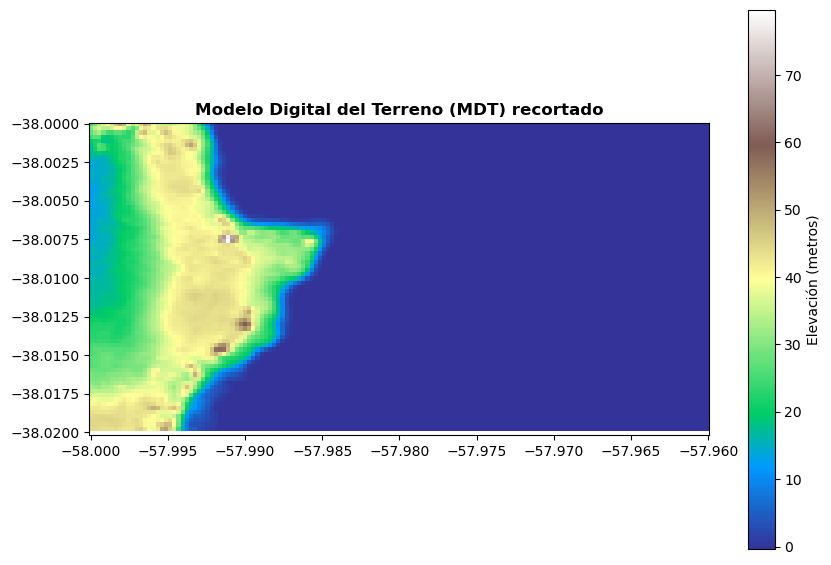

In [8]:
fig, ax = plt.subplots(figsize=(10, 10))
show(dtm_crop, 
     transform=transform, 
     ax=ax, 
     cmap='terrain', 
     title='Modelo Digital del Terreno (MDT) recortado')

cbar = plt.colorbar(ax.images[0], ax=ax, shrink=0.7)
cbar.set_label('Elevación (metros)')
plt.show()

**OpenStreetMap (OSM)** es un proyecto colaborativo y abierto que crea y mantiene un mapa mundial editable por cualquier persona, similar a una “Wikipedia del mapa”. Sus datos incluyen carreteras, edificios, puntos de interés, usos del suelo, servicios y miles de tipos de *features* descritas de forma comunitaria. Es gratuito, libre y utilizado ampliamente en SIG, aplicaciones móviles, investigación y desarrollo web.

- 🌍 **Web oficial:** https://www.openstreetmap.org  
- 📚 **Documentación (OSM Wiki):** https://wiki.openstreetmap.org/wiki/  
- 🏷️ **Página de etiquetado (todas las *features*, tags y convenciones):** https://wiki.openstreetmap.org/wiki/Map_features  


### Descargar la linea de costa desde OSM

In [14]:

extent_bbox = [lon_min,  lat_min,lon_max, lat_max]
gdf_costa = ox.features_from_bbox(extent_bbox, tags={"natural": "coastline"}) # ¡Puede tardar varios minutos!

# Proyectar al CRS del raster
costa = gdf_costa.to_crs(crs) #¡recorte tiene que estar en el mismo crs que costa!

# Recortar la línea de costa al área del DTM
costa_rec = costa.clip(recorte)


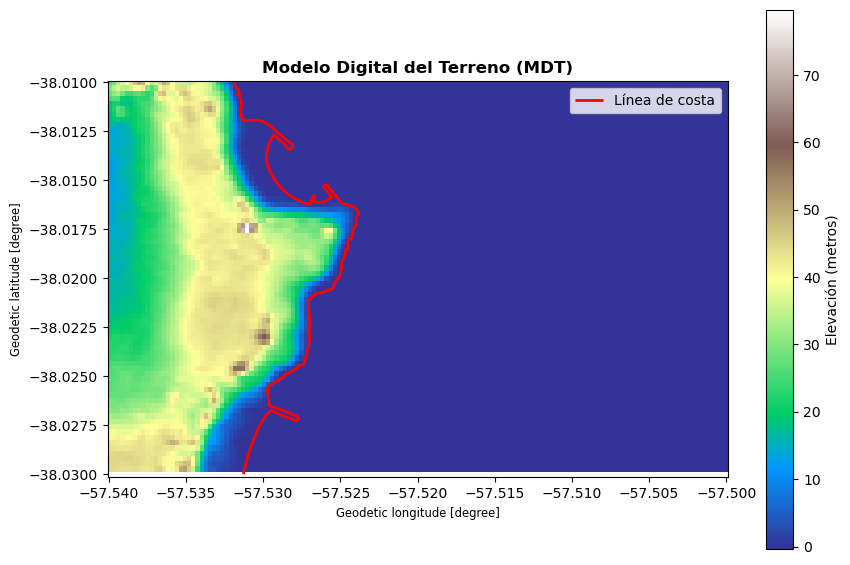

In [15]:
fig, ax = plt.subplots(figsize=(10, 10))
# Mostrar el DTM
show(dtm_crop, 
     transform=out_transform, 
     ax=ax, 
     cmap='terrain', 
     title='Modelo Digital del Terreno (MDT)')

costa_rec.plot(ax=ax, color='red', linewidth=2, label='Línea de costa')
cbar = plt.colorbar(ax.images[0], ax=ax, shrink=0.7)
cbar.set_label('Elevación (metros)')
ax.legend()
plt.show()

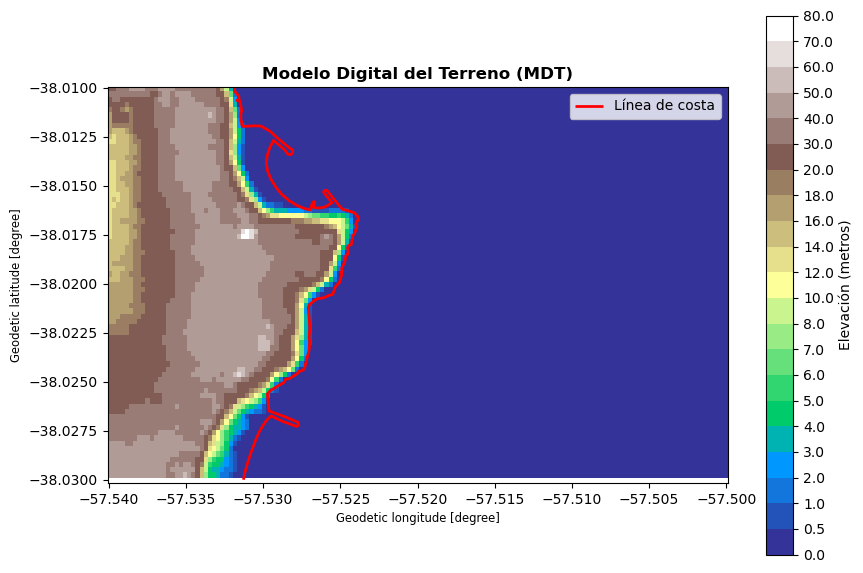

In [16]:


# Más resolución de color a cotas bajas
niveles = [0,0.5, 1, 2, 3,4,5,6,7, 8, 10, 12, 14, 16, 18, 20,30, 40, 50, 60, 70, 80]

fig, ax = plt.subplots(figsize=(10, 10))
cmap = plt.get_cmap('terrain')
norm = BoundaryNorm(niveles, ncolors=cmap.N, clip=True)

# Mostrar el DTM
show(
    dtm_crop,
    transform=out_transform,
    ax=ax,
    cmap=cmap,
    norm=norm,
    title='Modelo Digital del Terreno (MDT)'
)

# Línea de costa
costa_rec.plot(ax=ax, color='red',linewidth=2, label='Línea de costa')
# Barra de color
cbar = plt.colorbar( ax.images[0], ax=ax, shrink=0.7,ticks=niveles)
cbar.set_label('Elevación (metros)')

ax.legend()
plt.show()

### Rasterizar la línea de costa

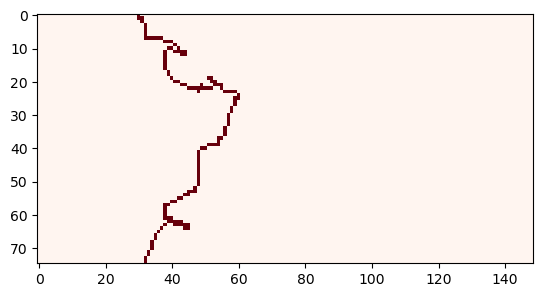

In [17]:
'''
Hasta ahora tenemos dos modelos de datos diferentes:
DTM --> ráster
costa --> vector

Para preguntar qué píxeles están conectados con la costa necesitamos que ambos estén en la misma rejilla.
'''

mask_costa = rasterize(
    [(geom, 1) for geom in costa_rec.geometry], # Geometrías a pintar, Le dice a rasterize: "dibuja esta geometría, y donde caiga, pon un 1" 
    out_shape=dtm_crop.shape, # Tamaño de la imagen (igual que tu raster), forma el array de destino
    transform=out_transform, # Donde está cada píxel (la georreferenciación). Le dice: "este píxel (fila, columna) está en tal lugar del mundo". Es como la “regla” para mapear coordenadas reales a píxeles.
    fill=0, # Qué valor poner donde NO hay línea
    dtype='uint8'  # Tipo de dato (número entero pequeño)
)

mask_bool = mask_costa.astype(bool) #Rasterio no admite valores booleanos porque los rasteres de almacenan en tipo numéricos

# Visualizacion rápida
plt.imshow(mask_bool, cmap='Reds')


### Crear máscara de inundación inicial

In [18]:
nivel_agua = 20   # m, escenario didáctico

# Píxeles con altura menor al agua → inundables 
bajo_nivel = dtm_crop < nivel_agua

# Semilla de inundación: costa + baja altura
semilla = mask_bool & bajo_nivel

¿Todo terreno situado por debajo de 20m estaría inundado?

In [19]:
# si miramos únicamente la elevación...
inundado = dtm_crop < nivel_agua
# Pero no basta con la elevación. El píxel tiene que estar conectado con el mar.

### Propagación tipo bathtub

In [20]:
# Estructura de vecindad
# ----------------------
#
# La inundación se propaga entre píxeles vecinos.
#
# Conectividad 4             Conectividad 8

#     X                       X X X
#   X O X                     X O X
#     X                       X X X
#
# Solo comparte lado         Comparte lado o esquina
#
# En este ejercicio utilizaremos conectividad 4.

estructura = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
], dtype=bool)

La elección entre conectividad 4 y 8 es una decisión del modelo. En una rejilla ráster, qué consideramos "conectado" condiciona el resultado de la inundación.

In [25]:
# ¿Y si queremos conectividad 8?
#estructura = np.ones((3, 3), dtype=bool)
'''
esto equivale a 
1 1 1
1 1 1
1 1 1
'''

'\nesto equivale a \n1 1 1\n1 1 1\n1 1 1\n'

In [26]:
# ¿Están conectadas estas dos zonas?
'''
0 1
1 0
'''

'\n0 1\n1 0\n'

In [27]:
# Empezamos únicamente desde los píxeles de costa que están por debajo del nivel del agua
inundado = semilla.copy()

# Propagar la inundación mientras existan nuevos píxeles conectados y situados bajo el nivel del agua
while True:

    # Expandir un píxel hacia los vecinos
    inundado_nuevo = binary_dilation(
        inundado,
        structure=estructura
    )

    # Solo pueden inundarse píxeles por debajo del nivel de agua
    inundado_nuevo = inundado_nuevo & bajo_nivel

    # Si no aparecen nuevos píxeles inundados, hemos terminado
    if np.array_equal(inundado, inundado_nuevo):
        break

    inundado = inundado_nuevo

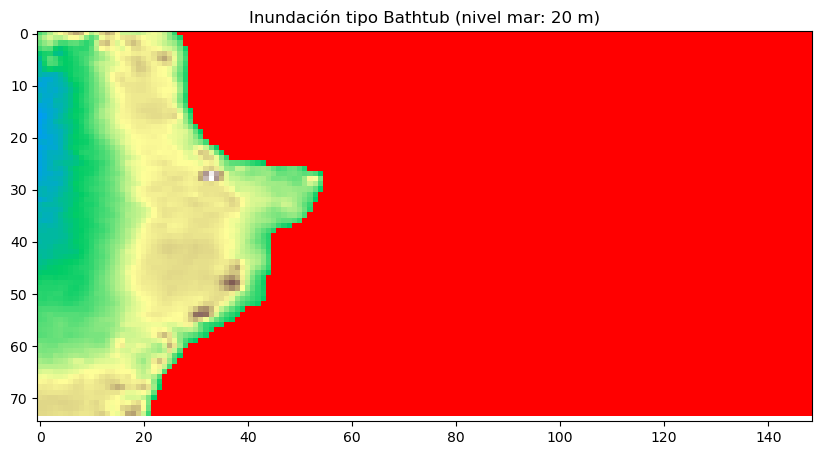

In [28]:
plt.figure(figsize=(10, 8))
plt.imshow(dtm_crop, cmap='terrain', alpha=1)
plt.imshow(np.ma.masked_where(~inundado, inundado), cmap=ListedColormap(['red']), alpha=1, vmin=0, vmax=1)
plt.title(f"Inundación tipo Bathtub (nivel mar: {nivel_agua} m)")
plt.show()


### OpenStreetMap (OSM)

**OpenStreetMap (OSM)** es una base de datos geográfica abierta y colaborativa que contiene información vectorial sobre elementos del territorio, como **carreteras, edificios, vías, costas y puntos de interés**.

En este tutorial utilizaremos los datos de OSM para obtener la **línea de costa** y los **edificios**, que posteriormente combinaremos con nuestro MDT.

**OSMnx** es una librería de Python que facilita la descarga y utilización de datos de OpenStreetMap directamente desde Python.

### Descargar edificios de OSM y evaluar impactos

In [31]:
# Visualización de la zona en https://www.openstreetmap.org/query?lat=-38.028884&lon=-57.531742#map=16/-38.02881/-57.53205
tags = {"building": True, "man_made": True}
edificios = ox.features_from_bbox(extent_bbox, tags=tags)
edificios = edificios.to_crs(crs)

In [35]:
edificios
#edificios['addr:city']
#edificios.columns
#edificios.tail()
#edificios.iloc[0]['addr:street' ]

geometry  \
element id                                                               
node    3740662300                         POINT (-57.53732 -38.02729)   
        4299036521                         POINT (-57.53365 -38.01327)   
        8178193437                         POINT (-57.53259 -38.01345)   
        12458011173                        POINT (-57.53714 -38.01013)   
        12458011174                        POINT (-57.53714 -38.01013)   
...                                                                ...   
way     1456406787   POLYGON ((-57.53181 -38.01199, -57.53182 -38.0...   
        1466142359   POLYGON ((-57.53605 -38.01135, -57.53617 -38.0...   
        1466142360   POLYGON ((-57.53572 -38.01096, -57.53581 -38.0...   
        1500111518   POLYGON ((-57.52807 -38.02215, -57.52807 -38.0...   
        1500111531   POLYGON ((-57.52819 -38.02194, -57.5282 -38.02...   

                         addr:city addr:housenumber addr:postcode  \
element id                                                          
node    3740662300   Mar del Plata             3751          7600   
        4299036521             NaN              NaN           NaN   
        8178193437             NaN              NaN           NaN   
        12458011173            NaN              NaN           NaN   
        12458011174            NaN              NaN           NaN   
...                            ...              ...           ...   
way     1456406787             NaN              NaN           NaN   
        1466142359             NaN              NaN           NaN   
        1466142360             NaN              NaN           NaN   
        1500111518             NaN              NaN           NaN   
        1500111531             NaN              NaN           NaN   

                              addr:street building  \
element id                                           
node    3740662300   Bernardo de Irigoyen   church   
        4299036521                    NaN      NaN   
        8178193437                    NaN      NaN   
        12458011173                   NaN      NaN   
        12458011174                   NaN      NaN   
...                                   ...      ...   
way     1456406787                    NaN      yes   
        1466142359                    NaN      yes   
        1466142360                    NaN      yes   
        1500111518                    NaN      yes   
        1500111531                    NaN      yes   

                                                    name      man_made  \
element id                                                               
node    3740662300             Nuestra Señora del Carmen           NaN   
        4299036521                                   NaN    water_well   
        8178193437                                   NaN      flagpole   
        12458011173                                  NaN  surveillance   
        12458011174                                  NaN  surveillance   
...                                                  ...           ...   
way     1456406787   Feria de Artesanos Torreón - Varese           NaN   
        1466142359                          La Fortaleza           NaN   
        1466142360            Cochera del Chalet Zamboni           NaN   
        1500111518                                   NaN           NaN   
        1500111531                          Villa Surula           NaN   

                    camera:direction camera:mount  ... roof:material  \
element id                                         ...                 
node    3740662300               NaN          NaN  ...           NaN   
        4299036521               NaN          NaN  ...           NaN   
        8178193437               NaN          NaN  ...           NaN   
        12458011173              124         pole  ...           NaN   
        12458011174              301         pole  ...           NaN   
...                            

### Convertir píxeles inundados a polígonos para análisis espacial

In [36]:
# esto crea un poligono por cada pixel inundado
rows, cols = np.where(inundado)

poligonos = []
for r, c in zip(rows, cols):
    x_min, y_max = rasterio.transform.xy(out_transform, r, c, offset='ul')
    x_max = x_min + out_transform.a
    y_min = y_max + out_transform.e
    poligonos.append(box(x_min, y_min, x_max, y_max))

gdf_inundados = gpd.GeoDataFrame(geometry=poligonos, crs=crs)
# Este método crea un polígono por cada píxel inundado. Es sencillo para entender la relación entre una celda del ráster y su representación vectorial, pero puede generar muchísimos polígonos y ser poco eficiente para rásteres grandes.

In [37]:
gdf_inundados
#gdf_inundados.plot()

,geometry
0,"POLYGON ((-57.53253 -38.01023, -57.53253 -38.0..."
1,"POLYGON ((-57.53226 -38.01023, -57.53226 -38.0..."
2,"POLYGON ((-57.53199 -38.01023, -57.53199 -38.0..."
3,"POLYGON ((-57.53172 -38.01023, -57.53172 -38.0..."
4,"POLYGON ((-57.53146 -38.01023, -57.53146 -38.0..."
...,...
8315,"POLYGON ((-57.501 -38.0299, -57.501 -38.02963,..."
8316,"POLYGON ((-57.50073 -38.0299, -57.50073 -38.02..."
8317,"POLYGON ((-57.50046 -38.0299, -57.50046 -38.02..."
8318,"POLYGON ((-57.50019 -38.0299, -57.50019 -38.02..."


In [38]:
# versión más eficiente con rasterio.features.shapes
# vectorizo la máscata de inundación. Se producen polígonos continuos y es mucho más escalable

# shapes() necesita valores numéricos
inundado_uint8 = inundado.astype("uint8")

# Extraer las zonas inundadas como geometrías
geometrias = []
for geom, valor in shapes(  #shapes() busca regiones de pixeles conectadas : recorre el ráster y busca grupos de píxeles contiguos que tienen el mismo valor.
    inundado_uint8, # Ráster con 0 = no inundado y 1 = inundado
    mask=inundado,  # Solo me interesa procesar las posiciones donde inundado == True
    transform=out_transform  # decirle a shapes donde estan los pixeles en el mundo real. Se transformas filas y columnas del array en coordeandas del crs (en este caso lat/lon)
):
        geometrias.append(shape(geom)) #shape() convierte la geometria GEOJSON que devuelve rasterio en un a geometria Shapely

# Crear GeoDataFrame: Ahora que tengo una lista de polígonos Shapely, creo un GeoDataFrame y le indico su CRS.
gdf_inundados = gpd.GeoDataFrame(
    geometry=geometrias,
    crs=crs
)
# rasterio.features.shapes() identifica regiones contiguas de píxeles con el mismo valor y las convierte directamente en geometrías vectoriales. Así evitamos crear manualmente un polígono para cada píxel.

Warning 1: DeprecationWarning: 'Memory' driver is deprecated since GDAL 3.11. Use 'MEM' onwards. Further messages of this type will be suppressed.


In [39]:
gdf_inundados
#gdf_inundados.plot()

,geometry
0,"POLYGON ((-57.5328 -38.00996, -57.5328 -38.010..."


In [40]:
'''
RÁSTER

0 0 0 0 0
0 1 1 0 0
0 1 1 1 0
0 0 1 1 0

       ↓ shapes()

VECTOR

   ┌─────┐
   │     └───┐
   │         │
   └───┐     │
       └─────┘
'''

'\nRÁSTER\n\n0 0 0 0 0\n0 1 1 0 0\n0 1 1 1 0\n0 0 1 1 0\n\n       ↓ shapes()\n\nVECTOR\n\n   ┌─────┐\n   │     └───┐\n   │         │\n   └───┐     │\n       └─────┘\n'

In [41]:
### Intersección edificio-inundación

In [50]:
impacto = gpd.sjoin(edificios, gdf_inundados, how="inner", predicate="intersects")
len(impacto)

geometry  \
element id                                                              
way     107666812   POLYGON ((-57.53028 -38.02575, -57.53032 -38.0...   
        314135415   POLYGON ((-57.52565 -38.01853, -57.5258 -38.01...   
        314139168   POLYGON ((-57.52518 -38.01768, -57.52518 -38.0...   
        315080739   POLYGON ((-57.5315 -38.012, -57.53153 -38.0120...   
        315189091   POLYGON ((-57.52697 -38.01632, -57.52695 -38.0...   
...                                                               ...   
        1452993743  POLYGON ((-57.5307 -38.013, -57.53072 -38.0130...   
        1452993744  POLYGON ((-57.53064 -38.01288, -57.53066 -38.0...   
        1452993745  POLYGON ((-57.53057 -38.01276, -57.53059 -38.0...   
        1452993746  POLYGON ((-57.5305 -38.01265, -57.53052 -38.01...   
        1456406787  POLYGON ((-57.53181 -38.01199, -57.53182 -38.0...   

                   addr:city addr:housenumber addr:postcode addr:street  \
element id                                                                
way     107666812        NaN              NaN           NaN         NaN   
        314135415        NaN              NaN           NaN         NaN   
        314139168        NaN              NaN           NaN         NaN   
        315080739        NaN              NaN           NaN         NaN   
        315189091        NaN              NaN           NaN         NaN   
...                      ...              ...           ...         ...   
        1452993743       NaN              NaN           NaN         NaN   
        1452993744       NaN              NaN           NaN         NaN   
        1452993745       NaN              NaN           NaN         NaN   
        1452993746       NaN              NaN           NaN         NaN   
        1456406787       NaN              NaN           NaN         NaN   

                      building                                 name man_made  \
element id                                                                     
way     107666812          yes                        La Normandina      NaN   
        314135415          yes                            La Pasiva      NaN   
        314139168   apartments                      Cabo Corrientes      NaN   
        315080739          NaN               Escollera Playa Varese   groyne   
        315189091          NaN                                  NaN   groyne   
...                        ...                                  ...      ...   
        1452993743   beach_hut                                  NaN      NaN   
        1452993744   beach_hut                                  NaN      NaN   
        1452993745   beach_hut                                  NaN      NaN   
        1452993746   beach_hut                                  NaN      NaN   
        1456406787         yes  Feria de Artesanos Torreón - Varese      NaN   

                   camera:direction camera:mount  ... wheelchair shelter_type  \
element id                                        ...                           
way     107666812               NaN          NaN  ...        NaN          NaN   
        314135415               NaN          NaN  ...        NaN          NaN   
        314139168               NaN          NaN  ...        NaN          NaN   
        315080739               NaN          NaN  ...        NaN          NaN   
        315189091               NaN          NaN  ...        NaN          NaN   
...                             ...          ...  ...        ...          ...   
        1452993743              NaN          NaN  ...        NaN          NaN   
        1452993744              NaN          NaN  ...        NaN          NaN   
        1452993745              NaN          NaN  ...        NaN          NaN   
        1452993746              NaN          NaN  ...        NaN          NaN   
        1456406787              NaN          NaN  ...        NaN          NaN   

                   natural club surface 

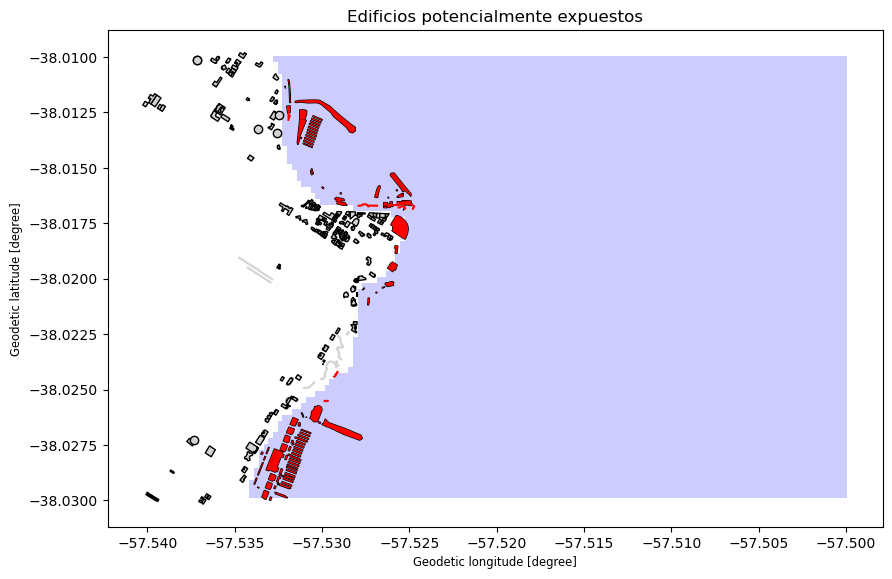

In [47]:
fig, ax = plt.subplots(figsize=(10, 10))
gdf_inundados.plot(ax=ax, color='blue', alpha=0.2)
edificios.plot(ax=ax, color='lightgrey', edgecolor='black')
impacto.plot(ax=ax, color='red')
plt.title("Edificios potencialmente expuestos")
plt.show()


# ¿Qué hemos modelado realmente?

### Sí considera:

-topografía.

-nivel de agua.

-conectividad con la costa.


### No considera:

-dinámica de la ola;

-tiempo de propagación;

-fricción;

-velocidad del flujo;

-run-up;

-oleaje;

-defensas costeras no representadas correctamente en el DTM;

-incertidumbre vertical del DTM.
